<br><h1 style="text-align: center;">Sentiment Analysis of Skytrax’s Airline Reviews</h1>
<p style="text-align: center;">by Ahmad Salehuddin Azzizi</p>
<img src="assets\img\airplane.jpeg">
<h2>1. Introduction</h2>
<p>For this assignment, we will go through several stages of workflow and the stages are as follows:</p>
<ol>
    <li>Acquire and load the data.</li>
    <li>Prepare and perform the data cleaning as well as removing any useless or extra fields.</li>
    <li>Analyse, identify patterns, and explore the data.</li>
    <li>Visualise the data.</li>
    <li>Perform sentiment analysis.</li>
</ol>

<h2>2. Importing Required Libraries</h2>
<p>Importing the libraries so that we will be able to use all the methods and functions offered by that particular packages later on.</p>

In [1]:
import pandas as pd
import seaborn as sns
import re
import string
from string import punctuation
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from afinn import Afinn
import matplotlib.pyplot as plt

<h2>3. Preparing and Loading the DataFrame</h2>
<p>We need to prepare and load the Airline Reviews DataFrame first into our Jupyter Notebook before we begin.</p>

In [2]:
airline_df = pd.read_csv('assets\csv_files\\airline_reviews.csv')
airline_df.head()

,airline,overall,author,review_date,customer_review,aircraft,traveller_type,cabin,route,date_flown,seat_comfort,cabin_service,food_bev,entertainment,ground_service,value_for_money,recommended
0,Turkish Airlines,7.0,Christopher Hackley,8th May 2019,London to Izmir via Istanbul. First time Iâ€™d...,NaN,Business,Economy Class,London to Izmir via Istanbul,May-19,4.0,5.0,4.0,4.0,2.0,4.0,yes
1,Turkish Airlines,2.0,Adriana Pisoi,7th May 2019,Istanbul to Bucharest. We make our check in in...,NaN,Family Leisure,Economy Class,Istanbul to Bucharest,May-19,4.0,1.0,1.0,1.0,1.0,1.0,no
2,Turkish Airlines,3.0,M Galerko,7th May 2019,Rome to Prishtina via Istanbul. I flew with th...,NaN,Business,Economy Class,Rome to Prishtina via Istanbul,May-19,1.0,4.0,1.0,3.0,1.0,2.0,no
3,Turkish Airlines,10.0,Zeshan Shah,6th May 2019,Flew on Turkish Airlines IAD-IST-KHI and retur...,A330,Solo Leisure,Economy Class,Washington Dulles to Karachi,Apr-19,4.0,5.0,5.0,5.0,5.0,5.0,yes
4,Turkish Airlines,1.0,Pooja Jain,6th May 2019,Mumbai to Dublin via Istanbul. Never book Turk...,NaN,Solo Leisure,Economy Class,Mumbai to Dublin via Istanbul,May-19,1.0,1.0,1.0,1.0,1.0,1.0,no


<h2>4. Printing the Column Names</h2>
<p>This method will return the column names available in the Airline Reviews DataFrame.</p>

In [3]:
print(airline_df.columns.values)

['airline' 'overall' 'author' 'review_date' 'customer_review' 'aircraft'
 'traveller_type' 'cabin' 'route' 'date_flown' 'seat_comfort'
 'cabin_service' 'food_bev' 'entertainment' 'ground_service'
 'value_for_money' 'recommended']


<h2>5. Removing Extra or Useless Fields of Data</h2>
<p>There are 17 columns altogether in the Airline Reviews DataFrame but not all of them will be used and utilised. Therefore, we need to remove the unnecessary columns before we can proceed to the analysing process.</p>
<p>For this assignment, we will be using columns such as:</p>
<ul>
    <li>airline - The name of airline such as: Qatar Airways, Singapore Airlines</li>
    <li>overall - The rating given by the customer based on scale from 1(Lowest) to 10(Highest) </li>
    <li>review_date - The date in which the review is given</li>
    <li>customer_review - The reviews made by the customer</li>
</ul>

In [4]:
airline_df = airline_df.drop(['author', 'aircraft', 'traveller_type', 'cabin', 
              'route', 'date_flown', 'seat_comfort', 'cabin_service', 'food_bev', 
              'entertainment', 'ground_service', 'value_for_money', 'recommended'], axis=1)

airline_df.dropna(inplace=True)
print(airline_df.columns.values)

['airline' 'overall' 'review_date' 'customer_review']


<h2>6. Splitting the Ratings into Two Categories</h2>
<p>Based on the rating given by the customer (overall), we split them into two categories; Positive and Negative.</p>
<p>
<pre>
    If the rating is above than 5, it will be considered as "Positive".
    Otherwise, it will be considered as "Negative"
</pre></p>

In [5]:
airline_df['reaction'] = airline_df['overall'].apply(lambda x: 'Positive' if x > 5 else 'Negative')

<h2>7. Displaying Basic Information of the Dataset</h2>
<p>Displaying some basic information of the Airline Reviews DataFrame.</p>

In [6]:
print("\n\033[1mBasic Info of the Dataset\033[0m")
print("_"*50)
print("\nTotal Review in the Dataset:", airline_df.overall.count(),"reviews")
print("Total Unique Airline:", airline_df.airline.nunique(),"airlines")


Basic Info of the Dataset
__________________________________________________

Total Review in the Dataset: 64017 reviews
Total Unique Airline: 81 airlines


<h2>8. Printing the Airline Companies</h2>
<p>This method will return the airline companies name available in the Airline Reviews DataFrame. There are 81 unique airline companies in the dataset.</p>

In [7]:
print(airline_df.airline.unique())

['Turkish Airlines' 'Qatar Airways' 'Emirates' 'Lufthansa'
 'KLM Royal Dutch Airlines' 'Virgin America' 'American Airlines'
 'Delta Air Lines' 'Southwest Airlines' 'United Airlines'
 'Jetblue Airways' 'Aegean Airlines' 'Aeroflot Russian Airlines'
 'Aeromexico' 'Air Canada' 'Air New Zealand' 'Alitalia' 'AirAsia'
 'Asiana Airlines' 'Avianca' 'Austrian Airlines' 'British Airways'
 'Brussels Airlines' 'China Eastern Airlines' 'China Southern Airlines'
 'Copa Airlines' 'Ethiopian Airlines' 'Egyptair' 'Finnair' 'Iberia'
 'ANA All Nippon Airways' 'easyJet' 'Korean Air' 'LATAM Airlines'
 'LOT Polish Airlines' 'Qantas Airways' 'Air France' 'Etihad Airways'
 'Pegasus Airlines' 'Royal Jordanian Airlines' 'Ryanair'
 'South African Airways' 'Saudi Arabian Airlines' 'TAP Portugal'
 'Eurowings' 'EVA Air' 'Royal Air Maroc' 'Singapore Airlines'
 'SAS Scandinavian' 'Swiss Intl Air Lines' 'Thai Airways' 'Air India'
 'Air Europa' 'Air Canada rouge' 'airBaltic' 'Air China'
 'Cathay Pacific Airways' 'Wizz A

<h2>9. Sorting and Prepare the Dataset for Analysing Purpose</h2>
<p>There are many airline companies in the dataset, but we would like to choose only two airline for analysing purpose and those are Qatar Airways and AirAsia.</p>

In [8]:
QatarAirways = pd.DataFrame([])
AirAsia = pd.DataFrame([])

QatarAirways = airline_df[airline_df['airline'] == 'Qatar Airways']
AirAsia = airline_df[airline_df['airline'] == 'AirAsia']

In [9]:
%matplotlib inline

<h2>10. Visualise the Data (Qatar Airways)</h2>
<p>We are trying to visualise the ratings given by the customer for Qatar Airways and we visualise them into a bar graph.</p>

<AxesSubplot:xlabel='overall', ylabel='count'>

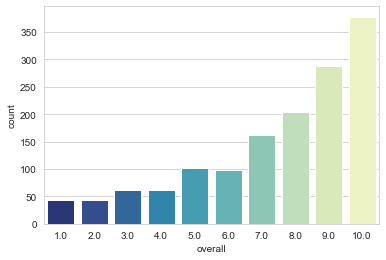

In [10]:
sns.set_style('whitegrid')
sns.countplot(x='overall',data=QatarAirways, palette='YlGnBu_r')

<AxesSubplot:xlabel='reaction', ylabel='count'>

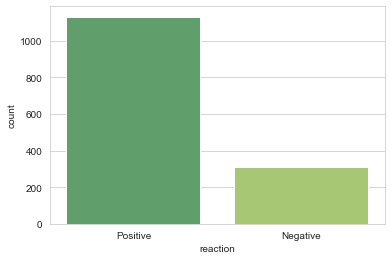

In [11]:
sns.set_style('whitegrid')
sns.countplot(x='reaction',data=QatarAirways, palette='summer')

<h2>11. Visualise the Data (AirAsia)</h2>
<p>We are trying to visualise the ratings given by the customer for AirAsia and we visualise them into a bar graph.</p>

<AxesSubplot:xlabel='overall', ylabel='count'>

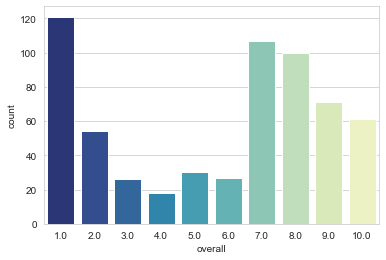

In [12]:
sns.set_style('whitegrid')
sns.countplot(x='overall',data=AirAsia, palette='YlGnBu_r')

<AxesSubplot:xlabel='reaction', ylabel='count'>

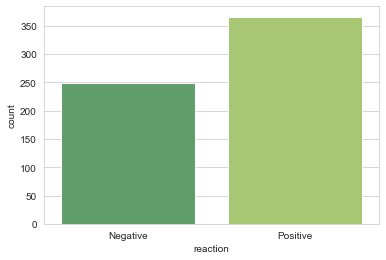

In [13]:
sns.set_style('whitegrid')
sns.countplot(x='reaction',data=AirAsia, palette='summer')

<h2>12. Visualise the Data (Overall)</h2>
<p>We are trying to visualise the ratings given by the customer as an overall and we visualise them into a bar graph.</p>

<AxesSubplot:xlabel='overall', ylabel='count'>

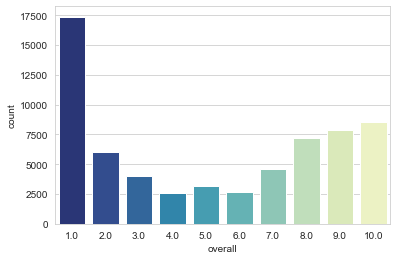

In [14]:
sns.set_style('whitegrid')
sns.countplot(x='overall',data=airline_df, palette='YlGnBu_r')

<AxesSubplot:xlabel='reaction', ylabel='count'>

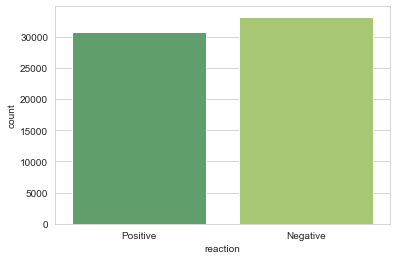

In [15]:
sns.set_style('whitegrid')
sns.countplot(x='reaction',data=airline_df, palette='summer')

<h2>13. Prepare the Data for Sentiment Analysing</h2>
<p>We are preparing to data to be used for sentiment analysis later on.</p>

In [16]:
qatarPositive = QatarAirways[QatarAirways['reaction'] == 'Positive'][0:1000]
qatarNegative = QatarAirways[QatarAirways['reaction'] == 'Negative']

In [17]:
qatarNegative_randomized = qatarNegative.sample(1000, replace=True)
QatarAirways = pd.concat([qatarPositive, qatarNegative_randomized], axis=0)

<h2>14. Removing Stopwords</h2>
<p>Any stopwords and punctuation such as "The", "a", "!" will be removed from the review texts so that it will help us to perform sentiment analysis.</p>

In [18]:
def get_text_processing(text):
 stpword = stopwords.words('english')
 no_punctuation = [char for char in text if char not in string.punctuation]
 no_punctuation = ''.join(no_punctuation)
 return ' '.join([word for word in no_punctuation.split() if word.lower() not in stpword])

In [19]:
QatarAirways['filtered_review'] = QatarAirways['customer_review'].apply(get_text_processing)
QatarAirways.head()

,airline,overall,review_date,customer_review,reaction,filtered_review
1491,Qatar Airways,6.0,8th May 2019,Doha to Hong Kong. Qatar Airways offer their s...,Positive,Doha Hong Kong Qatar Airways offer state art Q...
1492,Qatar Airways,9.0,8th May 2019,Bangkok to Gatwick via Doha. Ground service in...,Positive,Bangkok Gatwick via Doha Ground service Bangko...
1493,Qatar Airways,9.0,8th May 2019,Unbelievable level of personalised service eve...,Positive,Unbelievable level personalised service even c...
1494,Qatar Airways,10.0,6th May 2019,"Doha to Munich. Crew: Awesome, dedicated, beau...",Positive,Doha Munich Crew Awesome dedicated beautiful p...
1496,Qatar Airways,7.0,4th May 2019,Johannesburg to London via Doha. Normally I lo...,Positive,Johannesburg London via Doha Normally love Qat...


<h2>15. Sentiment Analysing with Afinn</h2>
<p>We split the reviews from the datasets and we let the machine to decide how much score will be given based on the keywords present in the review.</p>

In [20]:
afn = Afinn()

positive_df = qatarPositive['customer_review'].sample(10, replace=True)

positive_scores = [afn.score(article) for article in positive_df]

sentiment = ['positive' if score > 0
 else 'negative' if score < 0
 else 'neutral'
 for score in positive_scores]

df = pd.DataFrame()
df['topic'] = positive_df
df['scores'] = positive_scores
df['sentiments'] = sentiment
print(df)

                                                  topic  scores sentiments
2084  âœ… Verified Review | Hanoi to Bangkok with Qa...    13.0   positive
2546  Nice cabin on newish 777 Dreamliners PHL-Doha-...    13.0   positive
2295  London to Bangkok via Doha return. I have trav...    28.0   positive
2266  Riyadh to Lahore via Doha with Qatar Airways, ...    13.0   positive
2182  âœ… Verified Review | Flew Qatar Airways from ...    12.0   positive
2062  âœ… Verified Review | Kuala Lumpur to Abu Dhab...    17.0   positive
2005  âœ… Verified Review | Bangkok to Frankfurt via...    41.0   positive
2477  Dallas to Doha economy class, and passengers w...     5.0   positive
2054  âœ… Verified Review | Phnom Penh â€“ Saigon on...     2.0   positive
2744  BUD-DOH-SGN on 28-29 May 2014. Aircraft's A321...    23.0   positive


In [21]:
afn = Afinn()

negative_df = qatarNegative_randomized['customer_review'].sample(10, replace=True)

negative_scores = [afn.score(article) for article in negative_df]

sentiment = ['positive' if score > 0
 else 'negative' if score < 0
 else 'neutral'
 for score in negative_scores]

df2 = pd.DataFrame()
df2['topic'] = negative_df
df2['scores'] = negative_scores
df2['sentiments'] = sentiment
print(df2)

                                                  topic  scores sentiments
1737  Doha to Atlanta. When checking in in Atlanta d...    -9.0   negative
1749  On a recent flight from Barcelona to Adelaide ...    -1.0   negative
2220  âœ… Verified Review | I've flown Qatar Airways...   -13.0   negative
1564  Montreal to Colombo via Doha. Unfortunately, m...    -3.0   negative
2225  âœ… Verified Review | We were due to travel fr...    -8.0   negative
1894  âœ… Verified Review | Doha to Yangon. No infli...    -1.0   negative
1541  Bangkok to Milan via Doha. In the air they are...    -3.0   negative
1656  Doha to Milan after a six hours layover at Doh...    -1.0   negative
1602  Vienna to Denpasar via Doha on 11 October, whe...    -5.0   negative
2793  Melbourne to London via Doha. Late leaving Mel...    -7.0   negative


<h2>16. Generating WordCloud</h2>
<p>WordCloud are being generated based on the most-used-keywords in the dataset.</p>

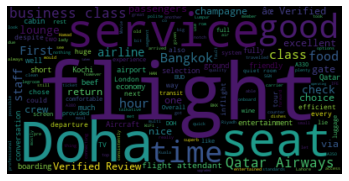

In [22]:
stpwrds = set(stopwords.words("english"))
fecthText = " ".join(review for review in df.topic)
wordcloud = WordCloud(stopwords=stpwrds).generate(fecthText)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.savefig('assets\img\wordcloud.png')
plt.show()